[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/paulrobustelli/CSMP_150_2026/blob/main/notebooks/Prinz_Potential_Transfer_Operator.ipynb)

# MSM theory: the four-well lecture, step by step
**CSMP 150 — companion to Robustelli's November 12, 2026 lecture**

Run all cells in order in Google Colab (Python 3). NumPy, SciPy, Matplotlib and IPython are the only dependencies. No files, credentials or MSM packages are required. The optional movie uses browser HTML, not an external video encoder.

**Numerical model:** a reversible, lazy, nearest-neighbor **Metropolis-chain discretization**, with 160 fixed reference states. Time is measured in **Monte Carlo steps**, including rejected proposals. It is not nanoseconds or calibrated molecular dynamics. We reproduce the lecture's computed examples, not the original paper's exact diffusion benchmark.

| Lecture PDF pages | Notebook sections |
|---|---|
| 6–12: assumptions, equilibrium, reversibility | 1–2 |
| 13–16: propagation, relative density, transfer operator | 3–4 |
| 17–21: repeated propagation and CK tests | 5–6 |
| 22–26: eigenfunctions and timescales | 7–8 |
| 27–35: mode amplitudes, reconstruction and relaxation | 9–11 |
| 39–42: discretization error | 12 and the trajectory-based examples |

Page numbers refer to `Robustelli_CSMP_MSM_Theory_Lecture_11.12.pdf` (42 pages). Paper figures in those slides illustrate the theory; they are not numerical outputs of this Metropolis model. Our plots below are computed, not screenshots.

## 1. Equilibrium and the potential
For a canonical ensemble (paper Eq. 3),
$$\mu(x)=Z^{-1}e^{-\beta H(x)},\qquad \beta=(k_BT)^{-1}.$$
For the one-dimensional configurational example, replace the Hamiltonian by the potential:
$$V(x)=2x^8+0.8e^{-80x^2}+0.2e^{-80(x-0.5)^2}+0.5e^{-40(x+0.5)^2}.$$
We use $x\in[-1,1]$, $\beta=5$. These are the **Prinz-style lecture variant's** parameters.

On the reference grid, $w_j\propto e^{-\beta V(x_j)}$ are **probability masses** with $\sum_jw_j=1$. We reserve $\pi_s$ for the equilibrium probability of a basin, $\mu(x)$ for a continuous density, and $u=p/\pi$ for relative population. Position and energy are dimensionless.

In [1]:
import sys
import numpy as np
import scipy
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
print("Python", sys.version.split()[0], "NumPy", np.__version__,
      "SciPy", scipy.__version__, "Matplotlib", matplotlib.__version__)

def potential(x):
    """Explicit lecture variant of the four-well Prinz potential."""
    return (2*x**8 + 0.8*np.exp(-80*x**2)
            + 0.2*np.exp(-80*(x-0.5)**2)
            + 0.5*np.exp(-40*(x+0.5)**2))

N_REFERENCE = 160
n = N_REFERENCE
beta = 5.0
proposal = 0.25  # Probability of proposing each neighboring move.
x = np.linspace(-1.0, 1.0, n)
energy = potential(x)

from scipy.integrate import quad
from IPython.display import display, HTML
from pathlib import Path
np.set_printoptions(precision=6, suppress=True)
COLORS = ["#8B0000", "#cf7c19", "#78952f", "#006080"]
BASINS = list("ABCD")
BASIN_EDGES = np.array([-1., -.5, 0., .5, 1.])

Python 3.12.7 NumPy 2.5.5 SciPy 1.18.1 Matplotlib 3.11.2


## 2. Fix the reference dynamics before building MSMs
Propose each neighboring move with probability $q=1/4$, accept with
$$P_{ij}=q\min(1,e^{-\beta(V_j-V_i)}),\qquad P_{ii}=1-\sum_{j\ne i}P_{ij}.$$
Proposals outside the domain are rejected. One attempt, including a rejection, is one MC step. Detailed balance (paper Eq. 4) is
$$\mu(x)p(x,y;\tau)=\mu(y)p(y,x;\tau),\qquad w_iP_{ij}=w_jP_{ji}.$$
The grid chain is connected and lazy: its equilibrium is unique and its spectrum is nonnegative. Reversibility alone does not imply a nonnegative spectrum.

The reference dynamics remain fixed when comparing MSM partitions. Changing grid spacing changes the distance moved per MC step and therefore changes the kinetics.

Equilibrium basin probabilities π: [0.106576 0.265809 0.414499 0.213117]


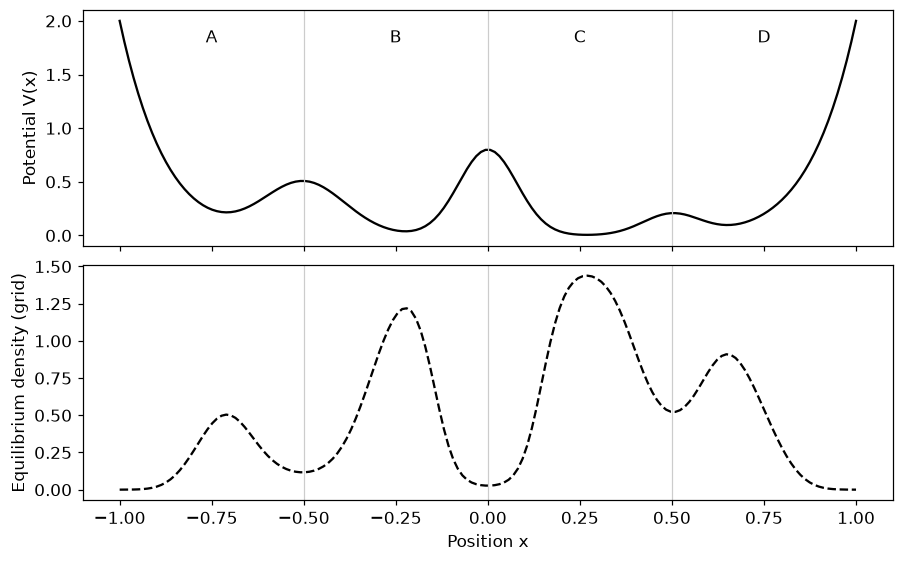

In [2]:
def metropolis_chain(energy, beta=5.0, proposal=0.25):
    """Return equilibrium masses and a lazy, nearest-neighbor transition matrix."""
    if beta < 0 or not 0 < proposal <= 0.25:
        raise ValueError("Use beta >= 0 and 0 < proposal <= 0.25")
    weights = np.exp(-beta * (energy - energy.min()))
    pi = weights / weights.sum()
    P = np.zeros((len(energy), len(energy)))
    for i in range(len(energy)):
        for j in (i-1, i+1):
            if 0 <= j < len(energy):
                # min(0, ...) avoids overflow for downhill moves.
                P[i, j] = proposal*np.exp(min(0., -beta*(energy[j]-energy[i])))
        P[i, i] = 1.0-P[i].sum()  # Rejections and unattempted moves.
    return pi, P


w, P = metropolis_chain(energy, beta, proposal)
np.testing.assert_allclose(P.sum(1), 1, atol=1e-14)
np.testing.assert_allclose(w @ P, w, atol=1e-14)
np.testing.assert_allclose(w[:, None]*P, w[None, :]*P.T, atol=1e-14)
assert P.min() >= 0 and np.diag(P).min() >= .5-1e-14
basin_labels = np.digitize(x, BASIN_EDGES[1:-1])
H4 = np.eye(4)[basin_labels]
pi4 = w @ H4
print("Equilibrium basin probabilities π:", pi4)
fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True, layout="constrained")
ax[0].plot(x, energy, "k"); ax[0].set_ylabel("Potential V(x)")
ax[1].plot(x, w/(x[1]-x[0]), "k--"); ax[1].set(xlabel="Position x", ylabel="Equilibrium density (grid)")
for a in ax:
    for edge in BASIN_EDGES[1:-1]: a.axvline(edge, color=".8", lw=.8)
for pos, name in zip([-.75,-.25,.25,.75], BASINS): ax[0].text(pos,1.8,name,ha="center")
plt.show()

## 3. The propagator and transfer operator: same dynamics, different representations
The conditional transition **density** $p(x,y;\tau)$ is different from the time-dependent ensemble density $p_t(x)$.

**Propagator (Eq. 5):**
$$p_{t+\tau}(y)=[Q(\tau)p_t](y)=\int_\Omega p(x,y;\tau)p_t(x)\,dx.$$
**Relative density (Eq. 7):**
$$u_t(x)=p_t(x)/\mu(x),\qquad p_t(x)=\mu(x)u_t(x).$$
**Transfer operator (Eq. 6):**
$$u_{t+\tau}(y)=[T(\tau)u_t](y)=\frac{1}{\mu(y)}\int_\Omega p(x,y;\tau)\mu(x)u_t(x)\,dx.$$
Thus $T=M_\mu^{-1}Q M_\mu$: multiply relative density by equilibrium, propagate, then divide by equilibrium. Both paths give the same physical population.

For a **row-stochastic matrix** $P$, rows are starting states and columns are destination states. Row probability vectors evolve as $p_{t+\tau}=p_tP^\tau$. With **column vectors**, $Q_\tau=(P^\tau)^T$ and $T_\tau=D_w^{-1}Q_\tau D_w=P^\tau$ by detailed balance. The heatmap of $P$ shows conditional transitions; the column-propagator matrix is its transpose.

The equilibrium-weighted inner product is
$$\langle f,g\rangle_w=\sum_jw_jf_jg_j.$$
Here $f$ and $g$ are any real functions on the states. Detailed balance makes $T$ self-adjoint in this inner product. This gives real eigenvalues and orthogonal modes; $Q$ has the same spectrum and is self-adjoint with the reciprocal equilibrium weight.

In [3]:
lag = 1000
P_lag = np.linalg.matrix_power(P, lag)
Q_lag = P_lag.T
T_lag = Q_lag * w[None, :] / w[:, None]
np.testing.assert_allclose(T_lag, P_lag, atol=1e-12)
p_demo = w*(1-.65*np.tanh(x/.1)); p_demo /= p_demo.sum()
u_demo = p_demo/w
np.testing.assert_allclose(Q_lag @ p_demo, w*(T_lag @ u_demo), atol=1e-12)
print("Propagating p and propagating u give the same population.")

Propagating p and propagating u give the same population.


## 4. Reference spectrum and equilibrium-conditioned projection
For the reversible one-MC-step matrix $P$, define $D_w=\operatorname{diag}(w_1,\ldots,w_n)$. We diagonalize the symmetric matrix
$$S=D_w^{1/2}PD_w^{-1/2}.$$
If $Sv_i=\ell_i v_i$, then the relative-density and probability-density eigenvectors are
$$\psi_i=D_w^{-1/2}v_i,\qquad \phi_i=D_w\psi_i.$$
In the fine-grid representation, the one-step transfer matrix is $T_1=P$ and the column-propagator matrix is $Q_1=P^T$. Therefore,
$$T_1\psi_i=\ell_i\psi_i,\qquad Q_1\phi_i=\ell_i\phi_i,\qquad \phi_i(j)=w_j\psi_i(j).$$
Here $\ell_i$ is an eigenvalue for **one MC step**. At integer lag $\tau$ MC steps,
$$T_\tau=P^\tau,\qquad Q_\tau=(P^\tau)^T,\qquad \lambda_i(\tau)=\ell_i^\tau.$$
The corresponding eigenvectors are unchanged by taking powers. The coarse-state eigenvalues below are separately computed from the coarse matrix; they need not equal these reference eigenvalues.

Let $H_{js}=1$ if fine-grid state $j$ belongs to MSM state $s$, and zero otherwise. The equilibrium probability of MSM state $s$ is
$$\pi_s=\sum_j w_jH_{js},\qquad D_\pi=\operatorname{diag}(\pi_1,\ldots,\pi_M).$$
The equilibrium-conditioned transition matrix at integer elapsed time $t$ MC steps is
$$T_H(t)=D_\pi^{-1}H^TD_wP^tH.$$
Its entry $[T_H(t)]_{ab}$ is the probability of ending in MSM state $b$, given a start in state $a$ drawn from equilibrium conditioned on that state.

This two-time conditional probability is exact for the reference chain. **It does not imply that the coarse-state process is Markovian.** Repeatedly applying $T_H(\tau)$ can introduce discretization error because a basin label loses information about position within the basin. Exact Markov coarse-graining is possible for special partitions; it is not guaranteed by reversibility.

T₄(1000), rows and columns A, B, C, D:
 [[0.794302 0.204496 0.001196 0.000005]
 [0.081992 0.885635 0.031223 0.00115 ]
 [0.000308 0.020023 0.792266 0.187403]
 [0.000003 0.001434 0.364488 0.634075]]


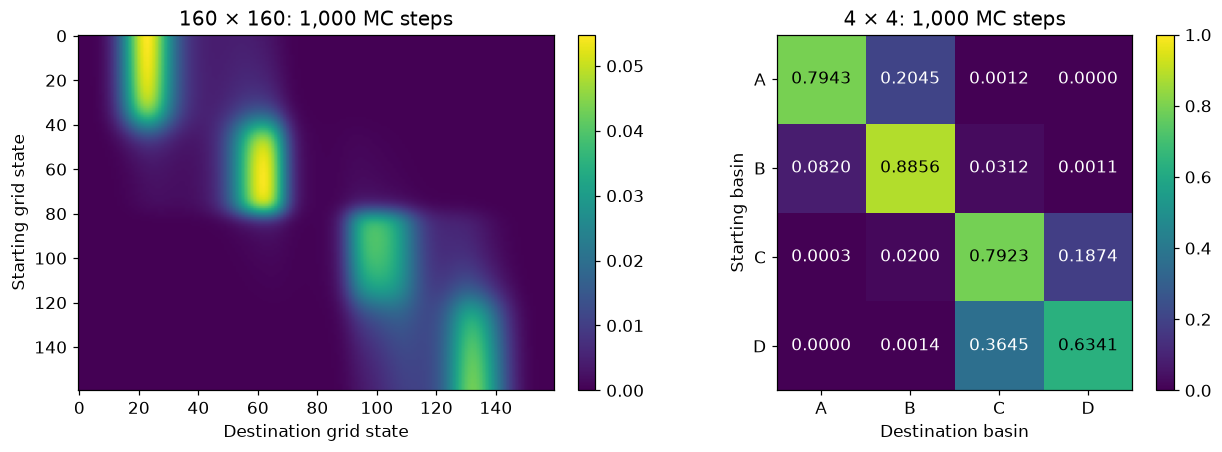

In [4]:
root = np.sqrt(w)
S = root[:, None]*P/root[None, :]
np.testing.assert_allclose(S, S.T, atol=1e-14)
ell, Vref = eigh(S)
ell, Vref = ell[::-1], Vref[:, ::-1]
psi_ref = Vref/root[:, None]
# Orient the leading modes to match the lecture. Signs are otherwise arbitrary.
for j, anchor in enumerate([0, n-1, 0, n-1]):
    if psi_ref[anchor, j] < 0:
        Vref[:, j] *= -1; psi_ref[:, j] *= -1
phi_ref = w[:, None]*psi_ref
np.testing.assert_allclose(P @ psi_ref, psi_ref*ell, atol=1e-10)
np.testing.assert_allclose(P.T @ phi_ref, phi_ref*ell, atol=1e-12)
np.testing.assert_allclose(psi_ref.T @ (w[:, None]*psi_ref), np.eye(n), atol=1e-12)

def projected_matrix(H, lag):
    """Exact reference conditional probabilities, not a trajectory estimate."""
    if int(lag) != lag or lag < 0: raise ValueError("lag must be a nonnegative integer")
    masses = w @ H
    if np.any(masses <= 0): raise ValueError("Partition has empty states")
    B = Vref.T @ (root[:, None]*H)
    # Spectral powers make repeated evaluations cheap without changing the result.
    joint = B.T @ ((ell**int(lag))[:, None]*B)
    return joint/masses[:, None]

def T4(lag): return projected_matrix(H4, lag)
for lag in [0, 100, 1000]:
    direct = (H4.T @ (w[:, None]*np.linalg.matrix_power(P, lag)) @ H4)/pi4[:, None]
    np.testing.assert_allclose(T4(lag), direct, atol=2e-12)
    np.testing.assert_allclose(T4(lag).sum(1), 1, atol=2e-12)
    np.testing.assert_allclose(pi4[:,None]*T4(lag), pi4[None,:]*T4(lag).T, atol=2e-12)
print("T₄(1000), rows and columns A, B, C, D:\n", T4(1000))
fig, ax = plt.subplots(1,2,figsize=(11,4),layout="constrained")
im=ax[0].imshow(P_lag,origin="upper",aspect="auto");fig.colorbar(im,ax=ax[0])
ax[0].set(xlabel="Destination grid state",ylabel="Starting grid state",title="160 × 160: 1,000 MC steps")
im=ax[1].imshow(T4(1000),vmin=0,vmax=1);fig.colorbar(im,ax=ax[1])
ax[1].set(xticks=range(4),xticklabels=BASINS,yticks=range(4),yticklabels=BASINS,xlabel="Destination basin",ylabel="Starting basin",title="4 × 4: 1,000 MC steps")
for i in range(4):
    for j in range(4): ax[1].text(j,i,f"{T4(1000)[i,j]:.4f}",ha="center",va="center",color="white" if T4(1000)[i,j]<.5 else "black")
plt.show()

## 5. Repeated propagation and the CK test
For the full Markov process (Eqs. 8–9),
$$Q(k\tau)=Q(\tau)^k,\qquadT(k\tau)=T(\tau)^k.$$
For the four-state approximation we **test**, rather than assume,
$$[T_4(\tau)^k]_{ab}\approx[T_4(k\tau)]_{ab}.$$
Blue lines: repeated four-state prediction. Black dots: direct longer-time evaluation of the reference chain, then projection. **Do not construct the black dots by raising the same four-state matrix to a power**; that would be a tautology.

The diagonal is return probability, allowing departure and return. It is not a survival probability. Agreement at $k=1$ is guaranteed here because both use the same exact lag-time matrix. Differences at later times are discretization error, not sampling noise. The 100-step row covers 1,000 total steps; the 1,000-step row covers 10,000. Compare the elapsed MC steps, $k\tau$, when interpreting the two rows; these are not calibrated physical times.

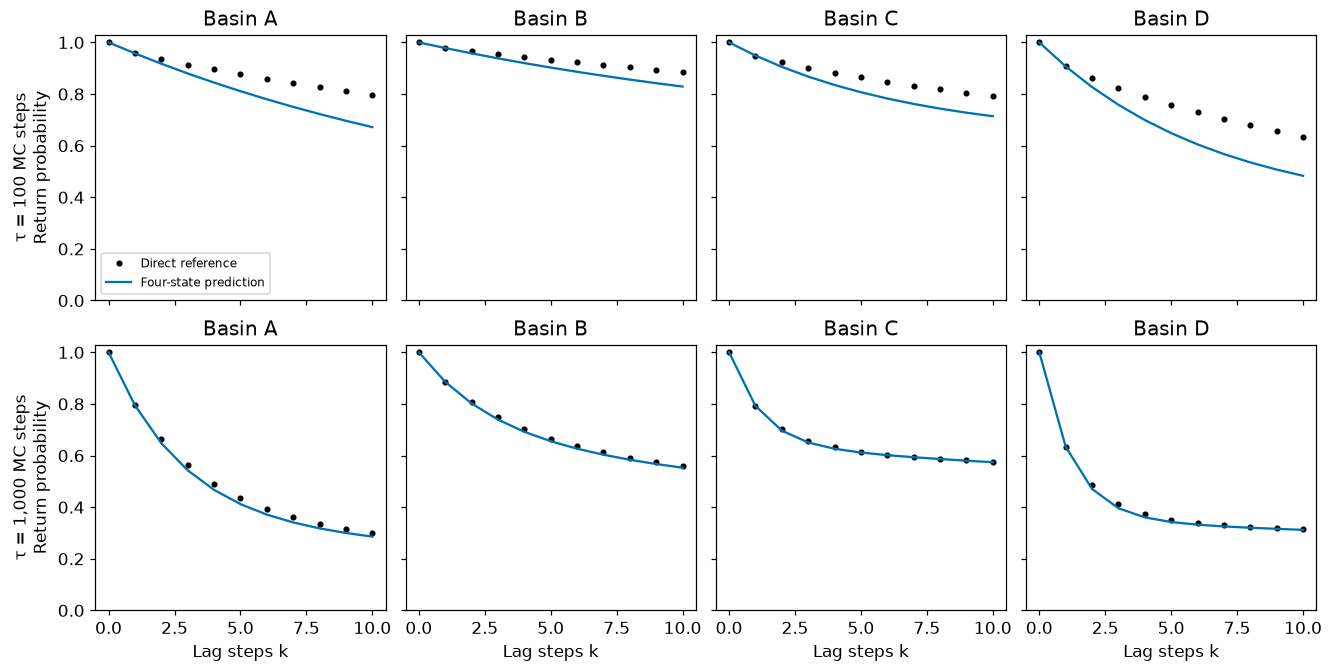

Maximum absolute error across all 16 entries and k=0…10: {100: np.float64(0.15093484382160777), 1000: np.float64(0.023908181785525784)}


In [5]:
K = np.arange(11)
def ck_arrays(lag):
    direct = np.array([T4(int(k*lag)) for k in K])
    predicted = np.array([np.linalg.matrix_power(T4(lag), int(k)) for k in K])
    return direct, predicted

fig, ax = plt.subplots(2,4,figsize=(12,6),sharex=True,sharey=True,layout="constrained")
ck_max = {}
for row, lag in enumerate([100,1000]):
    direct,predicted=ck_arrays(lag)
    ck_max[lag]=np.max(abs(direct-predicted))
    for s in range(4):
        ax[row,s].plot(K,direct[:,s,s],"ko",ms=3,label="Direct reference")
        ax[row,s].plot(K,predicted[:,s,s],color="#0072b2",label="Four-state prediction")
        ax[row,s].set(title=f"Basin {BASINS[s]}",ylim=(0,1.03))
        if s==0: ax[row,s].set_ylabel(f"τ = {lag:,} MC steps\nReturn probability")
        if row==1: ax[row,s].set_xlabel("Lag steps k")
ax[0,0].legend(fontsize=8);plt.show()
print("Maximum absolute error across all 16 entries and k=0…10:", ck_max)
np.testing.assert_allclose([ck_max[100],ck_max[1000]],[.1509348438,.0239082],atol=2e-6)

## 6. CK tests for all 16 transitions
Rows are starting basins; columns are destination basins. Every panel uses the same probability scale. Small absolute errors on rare transitions can still be large *relative* errors.

At short lag, a basin label forgets where the particle is inside the well. Repeated propagation implicitly restores the equilibrium conditional distribution inside each basin. Real trajectories retain information about their entry position. More resolved states can preserve more of this information.

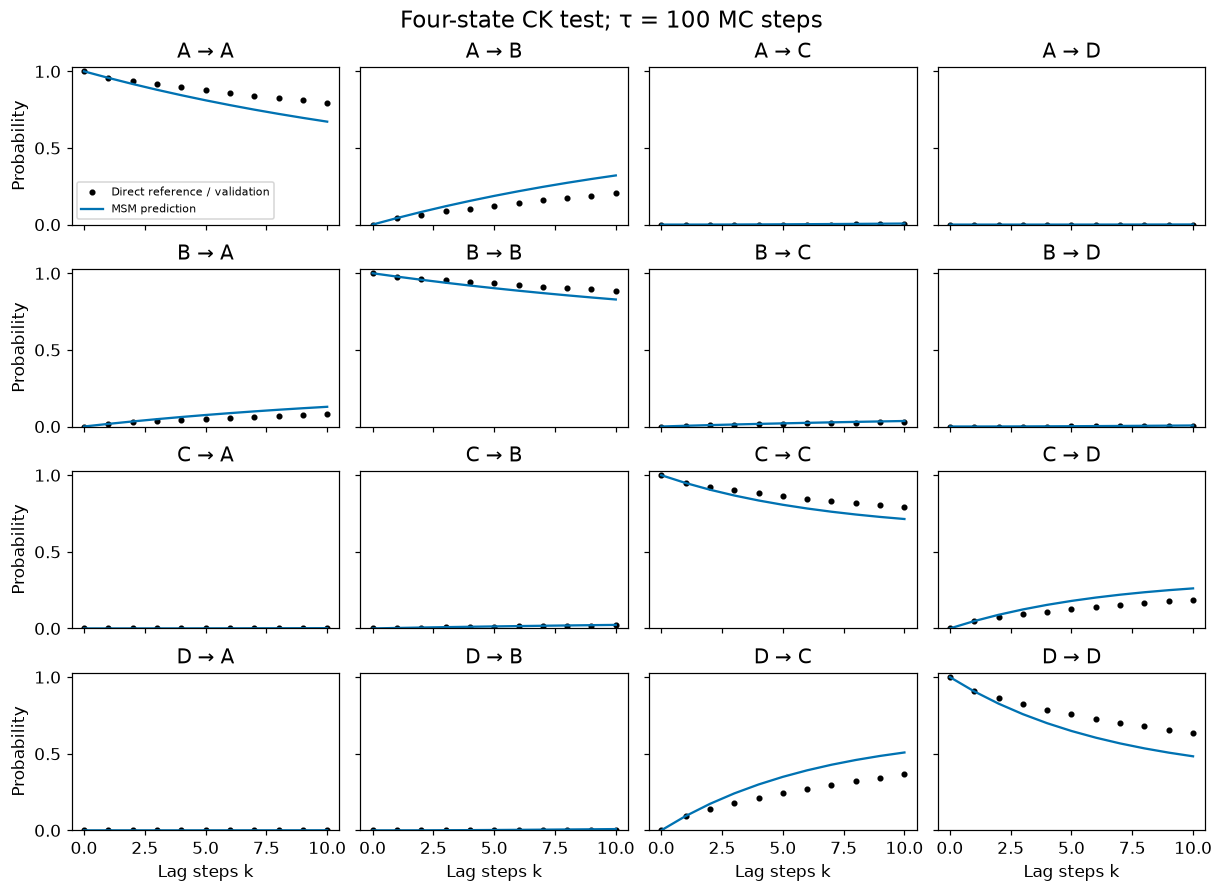

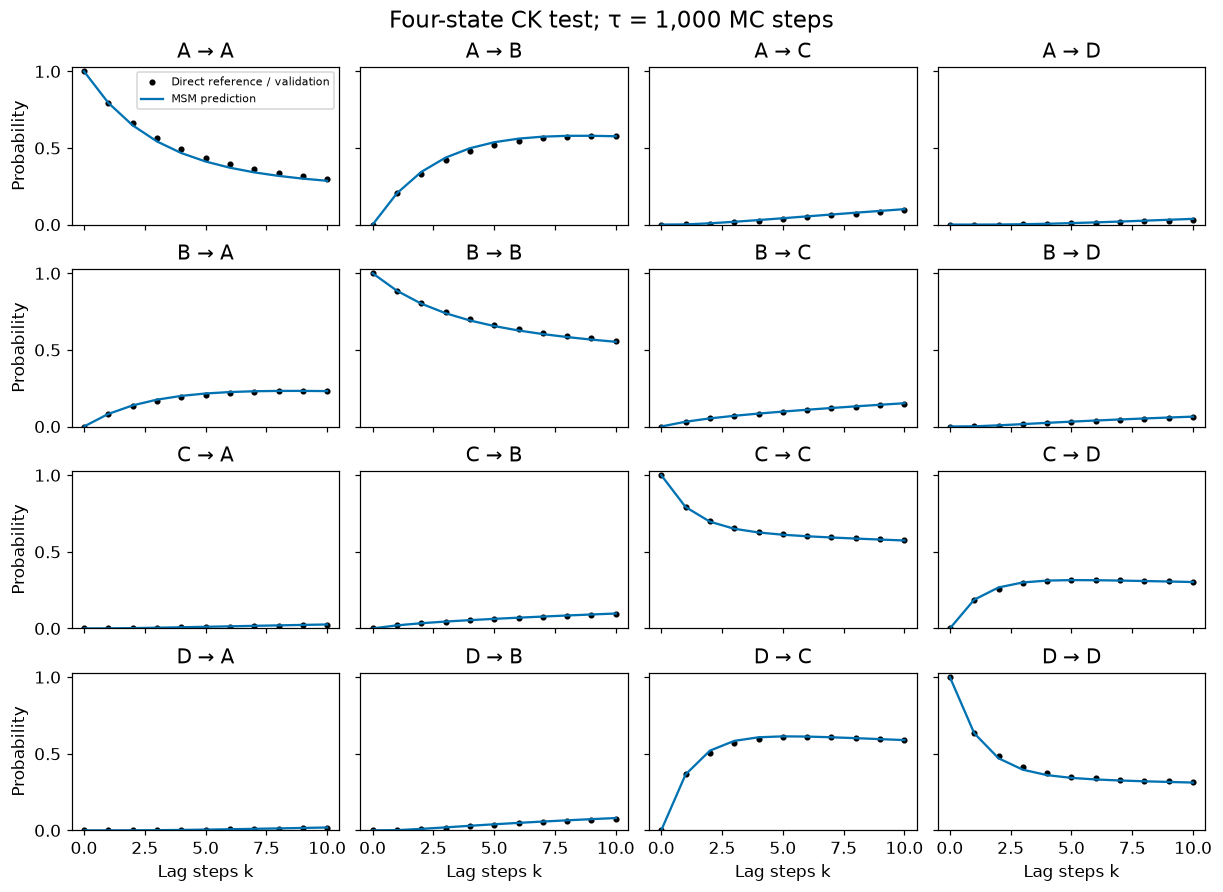

In [6]:
def plot_ck_grid(direct, predicted, lag, title="Four-state CK test"):
    fig, axes=plt.subplots(4,4,figsize=(11,8),sharex=True,sharey=True,layout="constrained")
    for i in range(4):
        for j in range(4):
            ax=axes[i,j]
            ax.plot(K,direct[:,i,j],"ko",ms=3,label="Direct reference / validation")
            ax.plot(K,predicted[:,i,j],color="#0072b2",label="MSM prediction")
            ax.set(title=f"{BASINS[i]} → {BASINS[j]}",ylim=(0,1.03))
            if j==0: ax.set_ylabel("Probability")
            if i==3: ax.set_xlabel("Lag steps k")
    axes[0,0].legend(fontsize=7)
    fig.suptitle(f"{title}; τ = {lag:,} MC steps",fontsize=15)
    plt.show()
for lag in [100,1000]: plot_ck_grid(*ck_arrays(lag),lag)

## 7. The actual four-state eigenvectors
At the lecture lag $\tau=1000$,
$$T_4\psi_i=\lambda_i\psi_i,\quad\phi_i=\pi\psi_i,\quad T_4^T\phi_i=\lambda_i\phi_i.$$
We normalize $\sum_s\pi_s\psi_i(s)\psi_j(s)=\delta_{ij}$ and orient the signs to match the slides. The stationary mode is $\psi_1=1$, $\phi_1=\pi$.

A four-state eigenvector has four values. Its step-function plot is not the smooth reference eigenfunction. The two resolutions have different numerical eigenvalues. Positive and negative lobes identify opposite sides of an imbalance; the coefficient's sign determines which side is overpopulated.

Eigenvalues: [1.       0.96423  0.702413 0.439635]
Right eigenvectors (rows A–D, columns modes 1–4):
 [[ 1.       -1.468934  2.494789 -0.035486]
 [ 1.       -1.224997 -1.121163  0.066922]
 [ 1.        0.743799  0.023933 -0.926683]
 [ 1.        0.815815  0.104219  1.73662 ]]


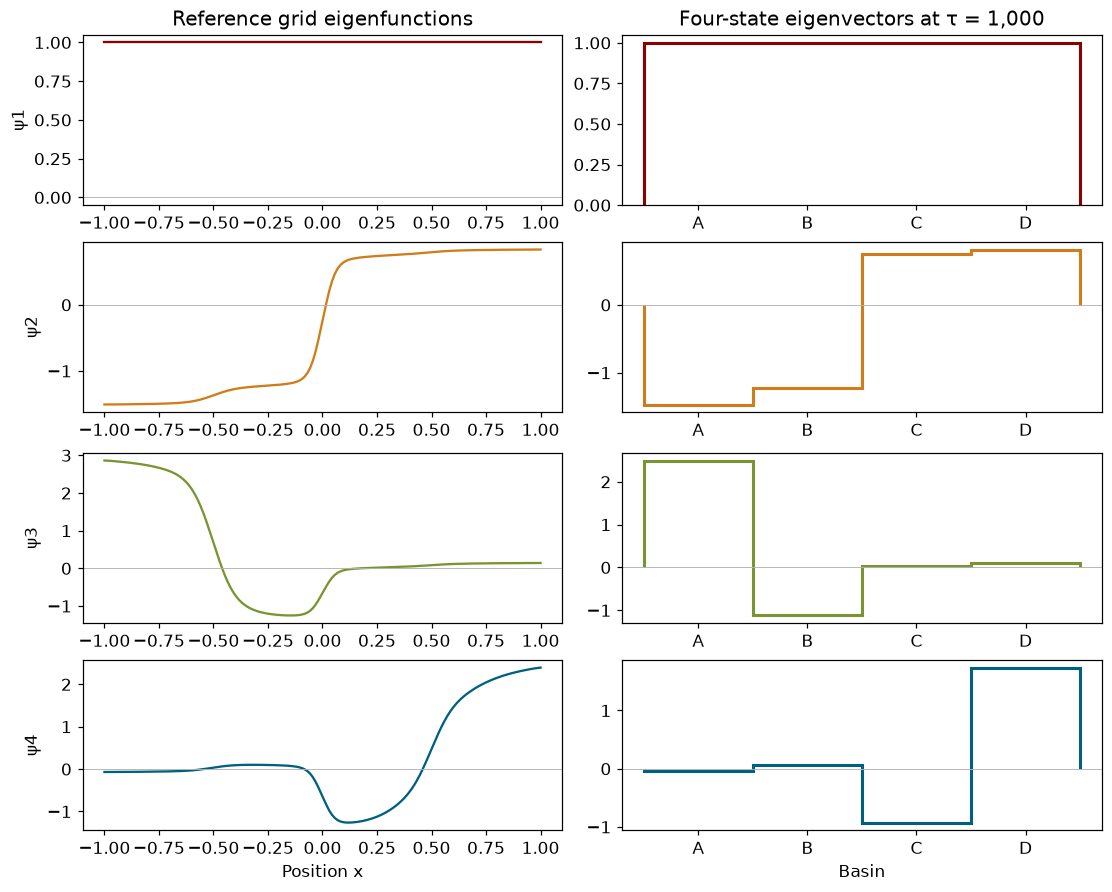

In [7]:
def reversible_modes(T, equilibrium):
    """Return descending eigenvalues and equilibrium-normalized right modes."""
    r=np.sqrt(equilibrium)
    sym=r[:,None]*T/r[None,:]
    np.testing.assert_allclose(sym,sym.T,atol=2e-11)
    values,vectors=eigh(sym)
    values=values[::-1]; vectors=vectors[:,::-1]/r[:,None]
    for j in range(vectors.shape[1]):
        anchor=np.argmax(abs(vectors[:,j]))
        if vectors[anchor,j]<0: vectors[:,j]*=-1
    return values,vectors

T_four=T4(1000)
lambda4,psi4=reversible_modes(T_four,pi4)
for j,anchor in enumerate([0,3,0,3]):
    if psi4[anchor,j]<0: psi4[:,j]*=-1
phi4=pi4[:,None]*psi4
print("Eigenvalues:",lambda4)
print("Right eigenvectors (rows A–D, columns modes 1–4):\n",psi4)
np.testing.assert_allclose(lambda4,[1,.96423042,.70241329,.43963485],atol=1e-8)
np.testing.assert_allclose(T_four@psi4,psi4*lambda4,atol=1e-12)
np.testing.assert_allclose(T_four.T@phi4,phi4*lambda4,atol=1e-12)
np.testing.assert_allclose(psi4.T@(pi4[:,None]*psi4),np.eye(4),atol=1e-12)
np.testing.assert_allclose(psi4[:,0],1,atol=1e-12)
fig,ax=plt.subplots(4,2,figsize=(10,8),layout="constrained")
for i in range(4):
    ax[i,0].plot(x,psi_ref[:,i],color=COLORS[i]);ax[i,0].set_ylabel(f"ψ{i+1}")
    ax[i,1].stairs(psi4[:,i],np.arange(5)-.5,color=COLORS[i],lw=2)
    ax[i,1].set_xticks(range(4),BASINS)
    for aa in ax[i]: aa.axhline(0,color=".7",lw=.6)
ax[0,0].set_title("Reference grid eigenfunctions")
ax[0,1].set_title("Four-state eigenvectors at τ = 1,000")
ax[-1,0].set_xlabel("Position x");ax[-1,1].set_xlabel("Basin");plt.show()

## 8. Eigenvalues and implied timescales
For positive nonstationary eigenvalues,
$$t_i(\tau)=-\frac{\tau}{\ln\lambda_i(\tau)}.$$
The stationary mode has infinite lifetime. A negative eigenvalue represents sign alternation, so this real exponential formula does not apply directly; do not silently take its absolute value. Our exact lazy reference chain avoids this complication.

The reference spectrum obeys lag invariance exactly. The coarse model's implied timescales can depend on lag. A plateau and a CK test are useful diagnostics, not proof of correctness. A spectral gap after four modes must be inspected, not inferred solely from the number of wells.

Four-state timescales at τ=1000 (MC steps): [27453.679229  2830.990053  1216.825124]


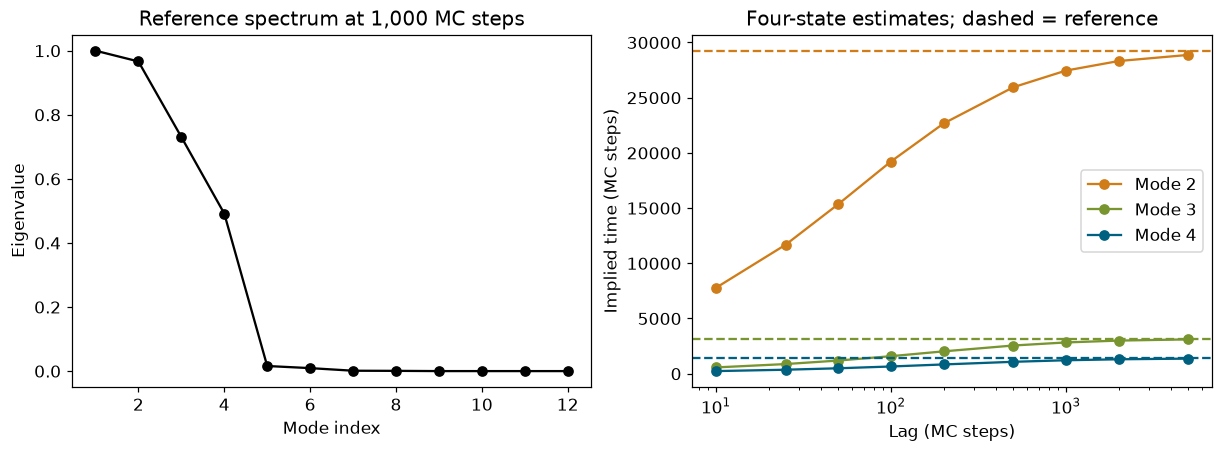

In [8]:
lags=np.array([10,25,50,100,200,500,1000,2000,5000])
coarse_times=[]
for lag in lags:
    val,_=reversible_modes(T4(int(lag)),pi4)
    assert np.all((val[1:]>0)&(val[1:]<1))
    coarse_times.append(-lag/np.log(val[1:]))
coarse_times=np.array(coarse_times)
print("Four-state timescales at τ=1000 (MC steps):",-1000/np.log(lambda4[1:]))
fig,ax=plt.subplots(1,2,figsize=(11,4),layout="constrained")
ax[0].plot(np.arange(1,13),ell[:12]**1000,"ko-")
ax[0].set(xlabel="Mode index",ylabel="Eigenvalue",title="Reference spectrum at 1,000 MC steps")
for i in range(3):
    ax[1].plot(lags,coarse_times[:,i],"o-",color=COLORS[i+1],label=f"Mode {i+2}")
    ax[1].axhline(-1/np.log(ell[i+1]),color=COLORS[i+1],ls="--")
ax[1].set(xlabel="Lag (MC steps)",ylabel="Implied time (MC steps)",title="Four-state estimates; dashed = reference",xscale="log")
ax[1].legend();plt.show()

## 9. Reproduce the lecture's initial distribution
The smooth continuous initial density is deliberately biased to the left:
$$\mu_c(x)=\frac{e^{-5V(x)}}{\int_{-1}^{1}e^{-5V(z)}dz},\qquad
p_0(x)=\frac{\mu_c(x)[1-0.65\tanh(x/0.1)]}{\int_{-1}^{1}\mu_c(z)[1-0.65\tanh(z/0.1)]dz}.$$
Compute basin populations by **integration**, not by reading peak heights:
$$p_{0,s}=\int_s p_0(x)dx,\qquad u_{0,s}=p_{0,s}/\pi_s.$$
To reproduce the lecture's numbers exactly, integrate this smooth density and use the four-state model's grid-derived equilibrium probabilities. Continuous quadrature and finite-grid equilibrium differ slightly; we name them separately rather than treating them as identical.

Initial basin probabilities: [0.211447 0.515687 0.182792 0.090074]
Relative populations: [1.984003 1.940068 0.440996 0.422651]


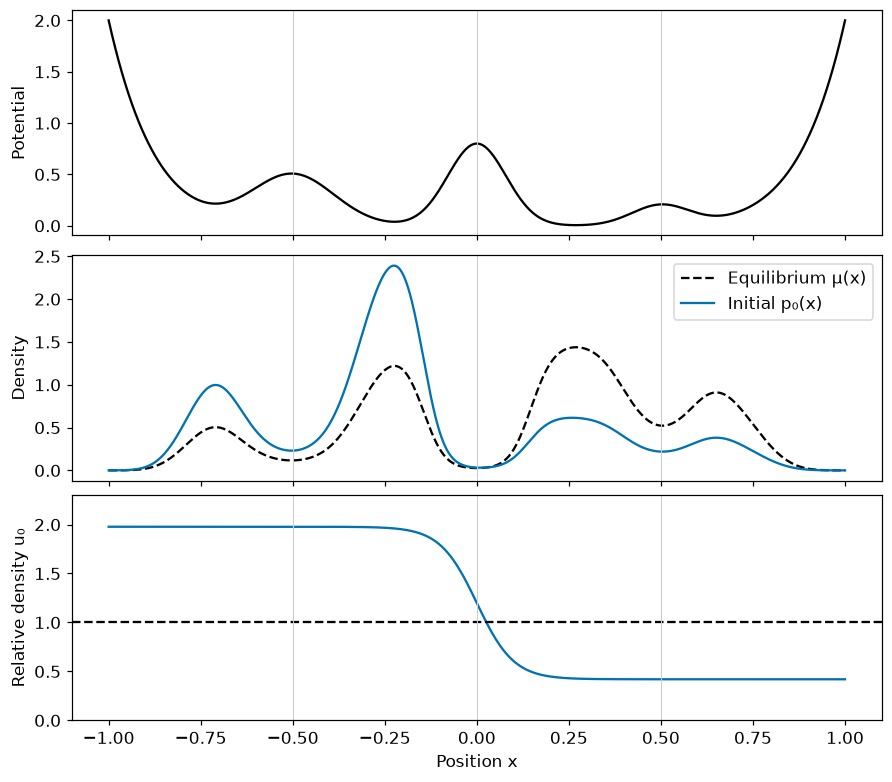

In [9]:
Z=quad(lambda z: np.exp(-beta*potential(z)),-1,1,epsabs=1e-12)[0]
def mu_cont(z): return np.exp(-beta*potential(z))/Z
Z_bias=quad(lambda z: mu_cont(z)*(1-.65*np.tanh(z/.1)),-1,1,epsabs=1e-12)[0]
def p0_cont(z): return mu_cont(z)*(1-.65*np.tanh(z/.1))/Z_bias
p0_four=np.array([quad(p0_cont,lo,hi,epsabs=1e-12)[0] for lo,hi in zip(BASIN_EDGES[:-1],BASIN_EDGES[1:])])
u0_four=p0_four/pi4
np.testing.assert_allclose(p0_four.sum(),1,atol=1e-12)
np.testing.assert_allclose(p0_four,[.2114466364,.5156871225,.1827922343,.0900740067],atol=1e-9)
print("Initial basin probabilities:",p0_four)
print("Relative populations:",u0_four)
xx=np.linspace(-1,1,2001)
fig,ax=plt.subplots(3,1,figsize=(8,7),sharex=True,layout="constrained")
ax[0].plot(xx,potential(xx),"k");ax[0].set_ylabel("Potential")
ax[1].plot(xx,mu_cont(xx),"k--",label="Equilibrium μ(x)")
ax[1].plot(xx,p0_cont(xx),color="#0072b2",label="Initial p₀(x)");ax[1].set_ylabel("Density");ax[1].legend()
ax[2].plot(xx,p0_cont(xx)/mu_cont(xx),color="#0072b2");ax[2].axhline(1,color="k",ls="--")
ax[2].set(xlabel="Position x",ylabel="Relative density u₀",ylim=(0,2.3))
for aa in ax:
    for edge in BASIN_EDGES[1:-1]: aa.axvline(edge,color=".8",lw=.7)
plt.show()

## 10. Calculate each amplitude, then reconstruct the imbalance
The continuous weighted inner product simplifies because $u_0\mu=p_0$:
$$a_i=\langle u_0,\psi_i\rangle_\mu=\int u_0\psi_i\mu\,dx=\int p_0\psi_i\,dx.$$
For our four-state modes,
$$a_i=\sum_s\pi_su_{0,s}\psi_i(s)=\sum_sp_{0,s}\psi_i(s).$$
**In words:** average the eigenvector's value over the starting population. These coefficients assume weighted-orthonormal modes. A mode's sign is arbitrary, but its coefficient changes sign with it, leaving $a_i\psi_i$ unchanged.

The lecture's mode 2 calculation is
$$a_2\approx(0.2114)(-1.4689)+(0.5157)(-1.2250)+(0.1828)(0.7438)+(0.0901)(0.8158)=-0.7329.$$
With all four modes there is no truncation remainder *within this four-state model*:
$$u_0(s)-1=\sum_{i=2}^{4}a_i\psi_i(s),\qquad p_{0,s}=\pi_su_0(s).$$
Negative $a_2$ multiplying negative mode values in A/B gives excess population on the left. Individual signed modes are not probability distributions.

Basin     p₀         π          u₀         ψ₂         p₀ ψ₂
  A    0.211447  0.106576  1.984003  -1.468934  -0.310601
  B    0.515687  0.265809  1.940068  -1.224997  -0.631715
  C    0.182792  0.414499  0.440996   0.743799   0.135961
  D    0.090074  0.213117  0.422651   0.815815   0.073484
Amplitudes (including stationary a₁=1): [ 1.       -0.732872 -0.036893  0.014041]


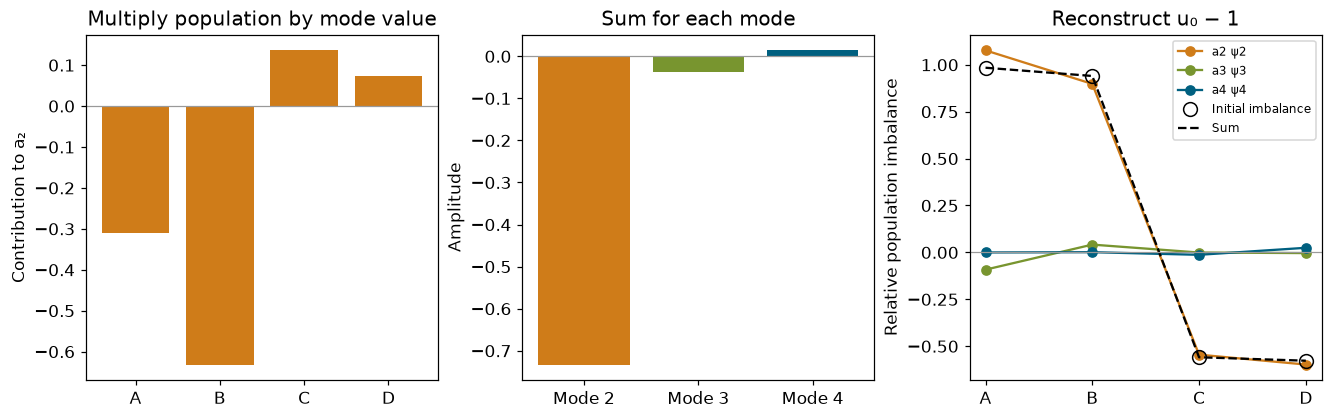

In [10]:
amplitudes=p0_four@psi4
products=p0_four[:,None]*psi4
print("Basin     p₀         π          u₀         ψ₂         p₀ ψ₂")
for s,name in enumerate(BASINS):
    print(f"{name:>3}   {p0_four[s]:9.6f} {pi4[s]:9.6f} {u0_four[s]:9.6f} {psi4[s,1]:10.6f} {products[s,1]:10.6f}")
print("Amplitudes (including stationary a₁=1):",amplitudes)
np.testing.assert_allclose(amplitudes,[1,-.7328719655,-.0368925123,.0140410981],atol=1e-9)
np.testing.assert_allclose(psi4@amplitudes,u0_four,atol=1e-12)
np.testing.assert_allclose(pi4*(psi4@amplitudes),p0_four,atol=1e-12)
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout="constrained")
ax[0].bar(BASINS,products[:,1],color=COLORS[1]);ax[0].set(title="Multiply population by mode value",ylabel="Contribution to a₂")
ax[1].bar(["Mode 2","Mode 3","Mode 4"],amplitudes[1:],color=COLORS[1:]);ax[1].set(title="Sum for each mode",ylabel="Amplitude")
for i in range(1,4): ax[2].plot(BASINS,amplitudes[i]*psi4[:,i],"o-",color=COLORS[i],label=f"a{i+1} ψ{i+1}")
ax[2].plot(BASINS,u0_four-1,"ko",mfc="none",ms=9,label="Initial imbalance")
ax[2].plot(BASINS,psi4[:,1:]@amplitudes[1:],"k--",label="Sum")
ax[2].set(title="Reconstruct u₀ − 1",ylabel="Relative population imbalance");ax[2].legend(fontsize=8)
for aa in ax: aa.axhline(0,color=".6",lw=.8)
plt.show()

## 11. Propagate the modes and rebuild the population
$$a_i(k)=a_i(0)\lambda_i^k,\quad u_k(s)=1+\sum_{i=2}^4a_i(k)\psi_i(s),\quad p_k(s)=\pi_su_k(s).$$
The equilibrium contribution stays fixed. The *imbalance* decays, not the total probability. These are predictions of repeated application of $T_4(1000)$, checked independently by matrix multiplication. They need not equal projection of the full process at $1000k$; that is the CK question.

The continuous density shown in the optional movie is a lift of basin populations using equilibrium shapes inside each basin. It preserves the initial basin probabilities but not every detail of the smooth initial curve. It is an instantaneous ensemble prediction, not the cumulative histogram of one MC trajectory.

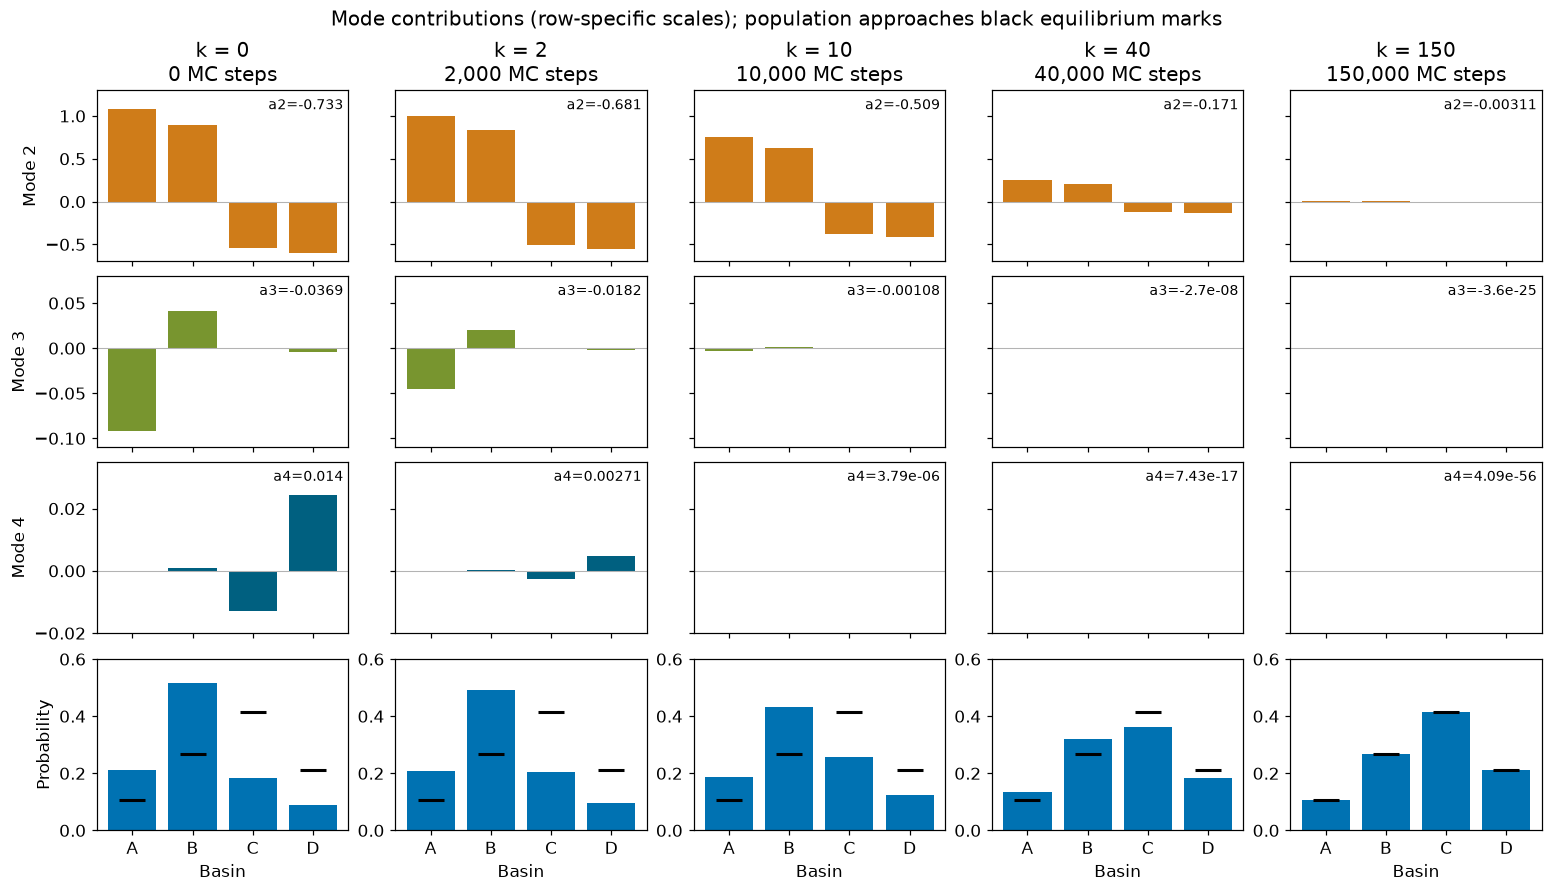

In [11]:
def population_at(k):
    if int(k)!=k or k<0: raise ValueError("Use a nonnegative integer lag count")
    coeff=amplitudes*(lambda4**int(k))
    relative=psi4@coeff
    return coeff,relative,pi4*relative

snapshots=[0,2,10,40,150]
fig,ax=plt.subplots(4,len(snapshots),figsize=(14,8),sharex=True,layout="constrained")
for col,k in enumerate(snapshots):
    coeff,relative,pop=population_at(k)
    np.testing.assert_allclose(pop,p0_four@np.linalg.matrix_power(T_four,k),atol=2e-12)
    np.testing.assert_allclose(pop.sum(),1,atol=2e-12);assert pop.min()>0
    for row in range(3):
        aa=ax[row,col];aa.bar(range(4),coeff[row+1]*psi4[:,row+1],color=COLORS[row+1])
        aa.axhline(0,color=".7",lw=.7)
        aa.set_ylim(*[(-.7,1.3),(-.11,.08),(-.02,.035)][row])
        aa.text(.98,.95,f"a{row+2}={coeff[row+1]:.3g}",transform=aa.transAxes,ha="right",va="top",fontsize=9)
        if col==0: aa.set_ylabel(f"Mode {row+2}")
        else: aa.tick_params(labelleft=False)
    ax[0,col].set_title(f"k = {k}\n{k*1000:,} MC steps")
    ax[3,col].bar(range(4),pop,color="#0072b2");ax[3,col].plot(range(4),pi4,"k_",ms=17,mew=2)
    ax[3,col].set(ylim=(0,.6),xticks=range(4),xticklabels=BASINS,xlabel="Basin")
    if col==0: ax[3,col].set_ylabel("Probability")
fig.suptitle("Mode contributions (row-specific scales); population approaches black equilibrium marks")
plt.show()

### Mode decay and equilibrium autocorrelation
An eigenvector's spatial shape stays fixed; its **amplitude** changes. Starting from the population above, project the propagated relative density back onto each mode:
$$a_i(k)=\sum_s\pi_s u_k(s)\psi_i(s)=a_i(0)\lambda_i^k.$$
For a nonstationary mode, its equilibrium mean is zero. Its normalized equilibrium autocorrelation in the four-state model is
$$C_i(k\tau)=\frac{\sum_{s,r}\pi_s\psi_i(s)[T_4(\tau)^k]_{sr}\psi_i(r)}{\sum_s\pi_s\psi_i(s)^2}=\lambda_i^k.$$
The code computes amplitudes by **matrix propagation and projection**, and correlations by the **equilibrium-weighted sum**, then checks both against the eigenvalue prediction. These are exact model calculations, not trajectory estimates. Dashed curves additionally evaluate the same basin observable in the reference chain at the full elapsed time; deviations measure the four-state approximation.

The constant equilibrium mode has amplitude 1 and never decays. Its centered autocorrelation is undefined (zero variance), so we plot modes 2–4 only. Time is in Monte Carlo steps. The lower panels use the actual calculated initial amplitudes, not equal illustrative amplitudes.

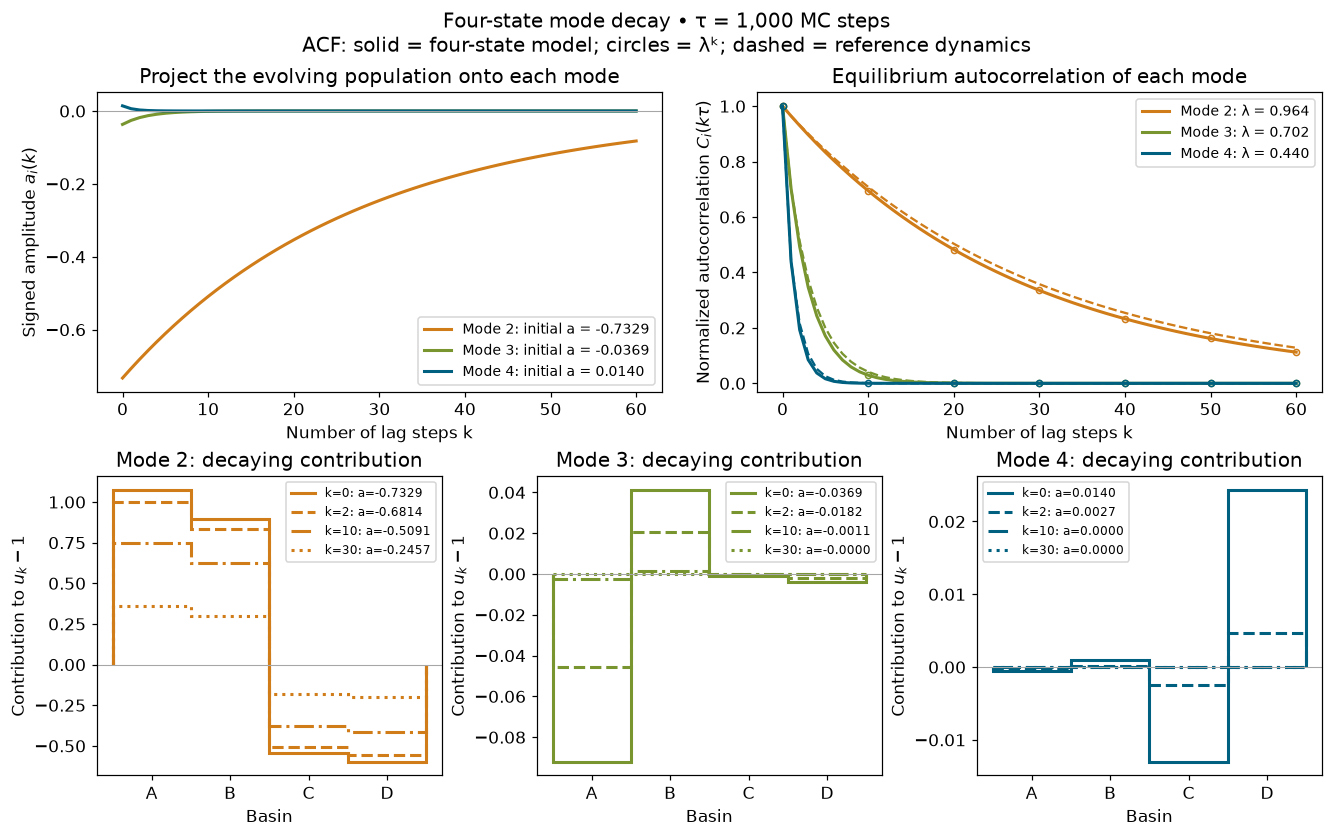

 k   elapsed MC steps       a₂          a₃          a₄
 0                  0   -0.732872   -0.036893    0.014041
 2              2,000   -0.681381   -0.018202    0.002714
10             10,000   -0.509139   -0.001079    0.000004
30             30,000   -0.245727   -0.000001    0.000000
60             60,000   -0.082391   -0.000000    0.000000
Relaxation times (MC steps): [27453.679229  2830.990053  1216.825124]


In [12]:
# Keep the lecture lag explicit: earlier cells also use a variable named lag.
mode_lag = 1000
mode_k = np.arange(61)
mode_amplitudes = []
mode_acf = []
reference_acf = []
for k in mode_k:
    Tk = np.linalg.matrix_power(T_four, int(k))
    pk = p0_four @ Tk
    uk = pk / pi4
    # Weighted projection of the current population onto every eigenvector.
    mode_amplitudes.append((pi4 * uk) @ psi4)
    # Rows are starting states, columns are destination states.
    mode_acf.append(np.sum(pi4[:, None] * psi4 * (Tk @ psi4), axis=0)
                    / np.sum(pi4[:, None] * psi4**2, axis=0))
    # Propagate the reference chain first, then observe its basin labels.
    direct = T4(int(k * mode_lag))
    reference_acf.append(np.sum(pi4[:, None] * psi4 * (direct @ psi4), axis=0)
                         / np.sum(pi4[:, None] * psi4**2, axis=0))
mode_amplitudes = np.asarray(mode_amplitudes)
mode_acf = np.asarray(mode_acf)
reference_acf = np.asarray(reference_acf)
predicted_decay = lambda4[None, :] ** mode_k[:, None]
np.testing.assert_allclose(mode_amplitudes, amplitudes * predicted_decay, atol=2e-11)
np.testing.assert_allclose(mode_acf, predicted_decay, atol=2e-11)
np.testing.assert_allclose(mode_amplitudes[:, 0], 1, atol=2e-11)
np.testing.assert_allclose(pi4 @ psi4[:, 1:], 0, atol=1e-12)

fig = plt.figure(figsize=(12, 7.5), layout="constrained")
grid = fig.add_gridspec(2, 6)
amp_ax = fig.add_subplot(grid[0, :3])
acf_ax = fig.add_subplot(grid[0, 3:])
for i in range(1, 4):
    color = COLORS[i]
    amp_ax.plot(mode_k, mode_amplitudes[:, i], color=color, lw=2,
                label=f"Mode {i+1}: initial a = {amplitudes[i]:.4f}")
    acf_ax.plot(mode_k, mode_acf[:, i], color=color, lw=2,
                label=f"Mode {i+1}: λ = {lambda4[i]:.3f}")
    acf_ax.plot(mode_k, reference_acf[:, i], color=color, ls="--", lw=1.5)
    # Selected computed points lie on the eigenvalue-power prediction.
    acf_ax.plot(mode_k[::10], predicted_decay[::10, i], "o", color=color,
                ms=4, fillstyle="none")
amp_ax.axhline(0, color=".65", lw=.7)
amp_ax.set(title="Project the evolving population onto each mode",
           ylabel=r"Signed amplitude $a_i(k)$", xlabel="Number of lag steps k")
acf_ax.set(title="Equilibrium autocorrelation of each mode",
           ylabel=r"Normalized autocorrelation $C_i(k\tau)$",
           xlabel="Number of lag steps k", ylim=(-.03, 1.05))
amp_ax.legend(fontsize=9); acf_ax.legend(fontsize=9)
for i in range(1, 4):
    ax = fig.add_subplot(grid[1, 2*(i-1):2*i])
    for k, style in zip([0, 2, 10, 30], ["-", "--", "-.", ":"]):
        ax.stairs(mode_amplitudes[k, i] * psi4[:, i], np.arange(5)-.5,
                  color=COLORS[i], ls=style, lw=2,
                  label=f"k={k}: a={mode_amplitudes[k, i]:.4f}")
    ax.axhline(0, color=".65", lw=.7)
    ax.set(title=f"Mode {i+1}: decaying contribution",
           xticks=range(4), xticklabels=BASINS, xlabel="Basin",
           ylabel=r"Contribution to $u_k-1$")
    ax.legend(fontsize=8)
fig.suptitle("Four-state mode decay • τ = 1,000 MC steps\n"
             "ACF: solid = four-state model; circles = λᵏ; dashed = reference dynamics")
plt.show()

print(" k   elapsed MC steps       a₂          a₃          a₄")
for k in [0, 2, 10, 30, 60]:
    print(f"{k:2d} {k*mode_lag:18,d} " + " ".join(f"{v:11.6f}" for v in mode_amplitudes[k, 1:]))
print("Relaxation times (MC steps):", -mode_lag / np.log(lambda4[1:]))


In [13]:
# Optional browser-native movie. Set True and rerun this cell in Colab.
# It advances one lag at a time; there is no fitted trajectory or interpolation.
RUN_MOVIE = False
if RUN_MOVIE:
    from matplotlib.animation import FuncAnimation
    plt.rcParams["animation.embed_limit"]=50
    fig,ax=plt.subplots(1,3,figsize=(12,3.8),layout="constrained")
    density_line,=ax[0].plot(x,w/(x[1]-x[0]),color="#0072b2")
    ax[0].plot(x,w/(x[1]-x[0]),"k--");ax[0].set(xlim=(-1,1),ylim=(0,2.7),xlabel="x",ylabel="Lifted density")
    relative_line,=ax[1].step(range(4),np.ones(4),where="mid",color="#0072b2")
    ax[1].axhline(1,color="k",ls="--");ax[1].set(xticks=range(4),xticklabels=BASINS,ylim=(0,2.3),ylabel="Relative population")
    bars=ax[2].bar(range(4),p0_four,color="#0072b2");ax[2].plot(range(4),pi4,"k_",ms=18)
    ax[2].set(xticks=range(4),xticklabels=BASINS,ylim=(0,.6),ylabel="Basin probability")
    title=fig.suptitle("")
    def update_movie(k):
        coeff,relative,pop=population_at(k)
        density_line.set_ydata(w/(x[1]-x[0])*(H4@relative))
        relative_line.set_ydata(relative)
        for bar,height in zip(bars,pop): bar.set_height(height)
        title.set_text(f"k={k}, time={1000*k:,} MC steps; a₂={coeff[1]:.3g}, a₃={coeff[2]:.3g}, a₄={coeff[3]:.3g}")
    movie=FuncAnimation(fig,update_movie,frames=range(151),interval=200)
    html=movie.to_jshtml();plt.close(fig);display(HTML(html))

## 12. Discretization: compare models on the same four observables
A finer MSM has $M$ states but should still predict the **same A–D basin transitions**. Otherwise, changing the dimension changes the meaning of the error metric.

For a refinement $H_M$ that never crosses an A–D boundary, let $G$ map its states to basins and
$$R_{as}=\Pr(\text{fine state }s\mid\text{basin }a,\text{equilibrium}).$$
The finer model's prediction is
$$\widehat B(k\tau)=R\,[T_M(\tau)]^kG.$$
It must retain the $M$ states during propagation. Collapsing to four states first and then taking powers throws the resolution away.

Below is a common exact-reference scoring function. It reports absolute probability error across all 16 basin transitions. More states often help, but state placement matters too. At $M=160$ we recover the reference chain's exact Markov description, which provides a consistency check.

In [14]:
def uniform_partition(M):
    """Partition fixed grid states into contiguous, equally sized MSM states."""
    if M<4 or M>n or n%M or M%4:
        raise ValueError("Choose M dividing 160 and divisible by 4")
    return np.eye(M)[np.arange(n)*M//n]

def basin_maps(H, equilibrium=w):
    """Equilibrium basin-to-MSM initialization R, and MSM-to-basin map G."""
    # Each MSM state must belong to exactly one of the original four basins.
    overlap=H.T@H4
    if not np.all((overlap>0).sum(1)==1): raise ValueError("MSM states must refine A–D")
    G=(overlap>0).astype(float)
    basin_mass=equilibrium@H4
    R=(H4.T@(equilibrium[:,None]*H))/basin_mass[:,None]
    return R,G

def exact_partition_score(M, lag=100):
    H=uniform_partition(M);R,G=basin_maps(H)
    Tm=projected_matrix(H,lag)
    prediction=np.array([R@np.linalg.matrix_power(Tm,int(k))@G for k in K])
    reference=np.array([T4(int(k*lag)) for k in K])
    return float(np.max(abs(prediction-reference))),prediction

baseline_error,_=exact_partition_score(4)
print(f"Four-state baseline at lag 100: {baseline_error:.6f}")
# Full-resolution consistency check.
full_error,_=exact_partition_score(160)
assert full_error<1e-10
print(f"160-state reference control: {full_error:.2e}")

Four-state baseline at lag 100: 0.150935
160-state reference control: 5.00e-15


## 13. Simulation-based MSM construction: supplied building blocks
Now introduce **sampling error** by estimating transitions from MC trajectories. A longer trajectory increases transition counts. It cannot eliminate the systematic four-state projection error. A finer partition reduces lost positional information, but usually needs more data.

The sampler below uses exactly the reference chain $P$, including rejections. Save every MC step. Different trajectories must be counted separately: never count a transition across a concatenation boundary. Seeds are explicit.

For counts $C_{ij}(\tau)$, we use the transparent reversible estimator
$$F=(C+C^T)/2,\quad\widehat\pi_i=\frac{\sum_jF_{ij}}{\sum_{ij}F_{ij}},\quad\widehat T_{ij}=F_{ij}/\sum_jF_{ij}.$$
This is **symmetrized-count estimation, not the reversible maximum-likelihood estimator**. It satisfies detailed balance by construction and is consistent for adequately sampled equilibrium trajectories. No pseudocounts are silently added. Unvisited or disconnected states are flagged; run more data or reconsider the partition rather than quietly deleting states or inventing transitions.

In [15]:
from scipy.sparse.csgraph import connected_components

def simulate_mc(n_steps, seed, start=None):
    """One fixed-reference trajectory; includes the state at time zero."""
    rng=np.random.default_rng(seed)
    state=int(rng.choice(n,p=w)) if start is None else int(start)
    path=np.empty(n_steps+1,dtype=np.int16);path[0]=state
    draws=rng.random(n_steps)
    for t,rnd in enumerate(draws,1):
        left=P[state,state-1] if state>0 else 0.
        right=P[state,state+1] if state<n-1 else 0.
        if rnd<left: state-=1
        elif rnd<left+right: state+=1
        path[t]=state
    return path

def transition_counts(paths, H, lag):
    """Sliding-window counts; paths remain independent at their boundaries."""
    if int(lag)!=lag or lag<1: raise ValueError("lag must be a positive integer")
    lag=int(lag);M=H.shape[1];assignment=H.argmax(1)
    counts=np.zeros((M,M),dtype=np.int64)
    for path in paths:
        states=assignment[np.asarray(path)]
        if len(states)<=lag: continue
        counts+=np.bincount(states[:-lag]*M+states[lag:],minlength=M*M).reshape(M,M)
    return counts

def fit_reversible_counts(counts):
    flux=(counts+counts.T)/2
    totals=flux.sum(1)
    if np.any(totals==0): raise ValueError("Unvisited states: collect more transitions")
    if connected_components(flux>0,directed=False,return_labels=False)!=1:
        raise ValueError("Disconnected count graph: collect inter-state transitions")
    fitted=flux/totals[:,None];stationary=totals/totals.sum()
    np.testing.assert_allclose(stationary[:,None]*fitted,stationary[None,:]*fitted.T,atol=1e-14)
    return fitted,stationary

def empirical_basin_transitions(paths, lag):
    counts=transition_counts(paths,H4,lag)
    if np.any(counts.sum(1)==0): raise ValueError("No validation origins in some basin")
    return counts/counts.sum(1)[:,None]

# Small deterministic checks catch lag and trajectory-boundary mistakes.
identity=np.eye(n)
c_test=transition_counts([np.array([0,1,2]),np.array([3,4,5])],identity,1)
assert c_test.sum()==4 and c_test[2,3]==0
assert transition_counts([np.array([0,1,2,3])],identity,2)[0,2]==1
path_check=simulate_mc(1000,seed=42)
assert np.all(abs(np.diff(path_check))<=1)
assert np.array_equal(path_check,simulate_mc(1000,seed=42))

### A short trajectory-based example (four-state baseline)
We start independent trajectories from the known equilibrium distribution, so burn-in is unnecessary for this controlled example. This does not make frames independent: MC samples remain correlated. For arbitrary starts, assess equilibration and discard an appropriate burn-in.

The training example is intentionally modest. We print count diagnostics and leading timescales rather than accepting a fit solely because it returns eigenvalues.

In [16]:
training_demo=[simulate_mc(100_000,seed=seed) for seed in [10,11,12,13]]
counts_demo=transition_counts(training_demo,H4,100)
T_demo,pi_demo=fit_reversible_counts(counts_demo)
values_demo,modes_demo=reversible_modes(T_demo,pi_demo)
print("Training transitions counted:",counts_demo.sum())
print("Counts by starting basin:",counts_demo.sum(1))
print("Estimated equilibrium:",pi_demo)
print("Estimated eigenvalues:",values_demo)
print("Timescales for eigenvalues in (0,1):")
for i,value in enumerate(values_demo[1:],2):
    print(i, -100/np.log(value) if 0<value<1 else "not a positive relaxation eigenvalue")
print("This short demonstration is not a convergence assessment.")

Training transitions counted: 399604
Counts by starting basin: [ 77894 171187  97271  53252]
Estimated equilibrium: [0.195138 0.428181 0.243442 0.133238]
Estimated eigenvalues: [1.       0.994237 0.935883 0.865103]
Timescales for eigenvalues in (0,1):
2 17302.660889328676
3 1509.0971366298722
4 690.0981230286916
This short demonstration is not a convergence assessment.


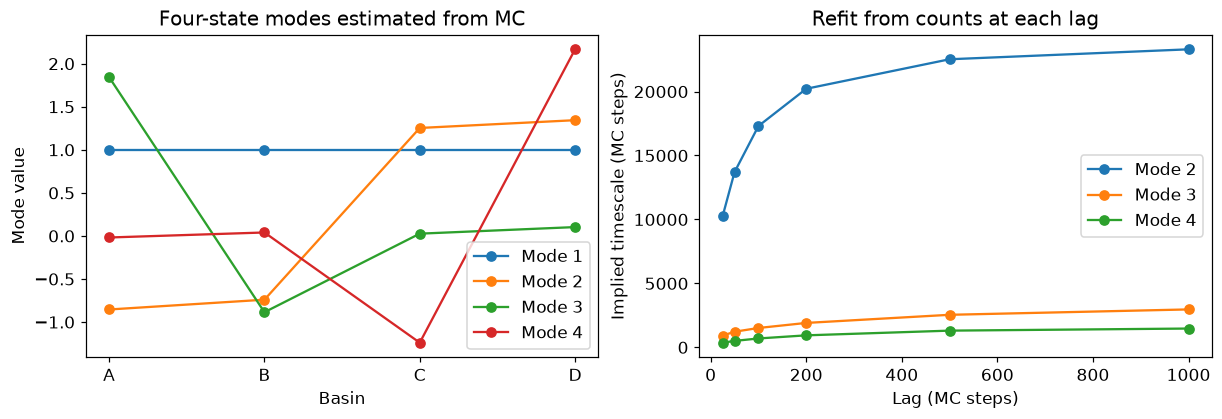

In [17]:
# Baseline plots from trajectory counts; reuse this pattern for finer partitions.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), constrained_layout=True)
for i in range(4):
    axes[0].plot(np.arange(4), modes_demo[:, i], marker="o", label=f"Mode {i+1}")
axes[0].set(xticks=np.arange(4), xticklabels=list("ABCD"), xlabel="Basin", ylabel="Mode value", title="Four-state modes estimated from MC")
axes[0].legend()
lag_grid = np.array([25, 50, 100, 200, 500, 1000])
fitted_times = []
for lag in lag_grid:
    fitted, stationary = fit_reversible_counts(transition_counts(training_demo, H4, int(lag)))
    values, _ = reversible_modes(fitted, stationary)
    fitted_times.append([-lag/np.log(v) if 0 < v < 1 else np.nan for v in values[1:4]])
for i in range(3):
    axes[1].plot(lag_grid, np.array(fitted_times)[:, i], "o-", label=f"Mode {i+2}")
axes[1].set(xlabel="Lag (MC steps)", ylabel="Implied timescale (MC steps)", title="Refit from counts at each lag")
axes[1].legend()
plt.show()


### Evaluating a fitted MSM
For the main benchmark we supply the exact equilibrium-conditional initializer $R$ so that all models are tested with the same starting ensembles. Only the transition matrix is fitted. This is a controlled diagnostic, not an assertion that equilibrium is known in a general molecular problem.

The validator below never uses the validation data for fitting.

In [18]:
def evaluate_fitted_msm(T_fitted, H, validation_paths, lag=100):
    R,G=basin_maps(H)  # Known reference initialization, explicitly supplied.
    predicted=np.array([R@np.linalg.matrix_power(T_fitted,int(k))@G for k in K])
    exact=np.array([T4(int(k*lag)) for k in K])
    observed=np.array([np.eye(4) if k==0 else empirical_basin_transitions(validation_paths,int(k*lag)) for k in K])
    return {"predicted":predicted,"validation":observed,"exact":exact,
            "max_error_vs_exact":float(np.max(abs(predicted[1:]-exact[1:]))),
            "max_error_vs_validation":float(np.max(abs(predicted[1:]-observed[1:])))}


## Numerical validation and limits
The executed lesson checks stochasticity, stationarity, detailed balance, the relationship between $Q$ and $T$, reference and coarse eigenpair residuals, weighted orthogonality, spectral versus matrix propagation, lecture values for eigenvalues and amplitudes, probability conservation, the 160-state CK control, and transition-count boundary handling.

The computed lecture figures use exact reference probabilities. The simulation section introduces a simple reversible count estimator, not a reversible maximum-likelihood estimator.

The original paper's exact diffusion parameters, theoretical error-bound figures and molecular systems are outside this numerical reproduction. The notebook follows the lecture's theory and generated Metropolis examples; it does not claim to reproduce every imported paper figure.

Reference: Prinz et al., *Markov models of molecular kinetics: Generation and validation*, J. Chem. Phys. **134**, 174105 (2011), [DOI](https://doi.org/10.1063/1.3565032), [full paper](https://publications.imp.fu-berlin.de/944/1/11_JCP_PrinzEtAl-MSM1.pdf).

## Homework 1

Determine the number of states needed to estimate an MSM of the one-dimensional Prinz potential that passes the Chapman–Kolmogorov (CK) test at a lag of **100 MC steps**.


In [ ]:
# Independent training and validation data for the state-resolution test.
N_PATHS = 8
PATH_LENGTH = 750_000
LAG_CK = 100
train_paths_ck = [simulate_mc(PATH_LENGTH, seed=3000+s) for s in range(N_PATHS)]
validation_paths_ck = [simulate_mc(PATH_LENGTH, seed=4000+s) for s in range(N_PATHS)]

candidate_M = [4, 8, 16, 20, 32, 40, 80]
ck_results = {}
for M in candidate_M:
    H = uniform_partition(M)
    counts = transition_counts(train_paths_ck, H, LAG_CK)
    try:
        T_fit, pi_fit = fit_reversible_counts(counts)
        R, G = basin_maps(H)
        pred = np.array([R @ np.linalg.matrix_power(T_fit, int(k)) @ G for k in K])
        exact = np.array([T4(int(k*LAG_CK)) for k in K])
        ck_results[M] = {
            "prediction": pred, "counts": counts,
            "min_origin_count": int(counts.sum(1).min()),
            "max_error_exact": float(np.max(np.abs(pred[1:] - exact[1:]))),
            "max_error_exact_projection": exact_partition_score(M, LAG_CK)[0],
        }
    except ValueError as exc:
        ck_results[M] = {"error": str(exc),
                         "min_origin_count": int(counts.sum(1).min())}

def basin_counts_for_path(path, lag):
    states = H4.argmax(1)[path]
    return np.bincount(states[:-lag]*4 + states[lag:],
                       minlength=16).reshape(4, 4)

ck_lags = [100*k for k in range(1, 11)]
validation_counts_by_lag = {
    lag: np.array([basin_counts_for_path(path, lag)
                   for path in validation_paths_ck])
    for lag in ck_lags
}

# Cluster bootstrap: resample whole independent trajectories, not individual frames.
rng_ck = np.random.default_rng(2026)
N_BOOT = 500
validation_ci = {}
validation_mean = {}
for lag in ck_lags:
    path_counts = validation_counts_by_lag[lag]
    pooled = path_counts.sum(axis=0)
    validation_mean[lag] = pooled / pooled.sum(axis=1, keepdims=True)
    boot = []
    for _ in range(N_BOOT):
        selected = rng_ck.integers(0, N_PATHS, size=N_PATHS)
        c = path_counts[selected].sum(axis=0)
        boot.append(c / c.sum(axis=1, keepdims=True))
    validation_ci[lag] = np.quantile(np.asarray(boot), [0.025, 0.975], axis=0)


for M, result in ck_results.items():
    if "prediction" not in result:
        print(f"M={M:>3}: not estimable ({result['error']}); min origin count={result['min_origin_count']}")
        continue
    pred = result["prediction"]
    obs = np.array([np.eye(4)] + [validation_mean[lag] for lag in ck_lags])
    result["max_error_validation"] = float(np.max(np.abs(pred[1:] - obs[1:])))
    outside = 0
    for k, lag in enumerate(ck_lags, start=1):
        lo, hi = validation_ci[lag]
        outside += int(np.sum((pred[k] < lo) | (pred[k] > hi)))
    result["outside_pointwise_CI"] = outside
    print(f"M={M:>3}: exact-projection error={result['max_error_exact_projection']:.5f}, "
          f"fitted-vs-exact={result['max_error_exact']:.5f}, "
          f"fitted-vs-validation={result['max_error_validation']:.5f}, "
          f"min origin count={result['min_origin_count']}, "
          f"points outside 95% CI={outside}/160")


M=  4: exact-projection error=0.15093, fitted-vs-exact=0.14752, fitted-vs-validation=0.16174, min origin count=662237, points outside 95% CI=139/160
M=  8: exact-projection error=0.13097, fitted-vs-exact=0.12789, fitted-vs-validation=0.14210, min origin count=163432, points outside 95% CI=139/160
M= 16: exact-projection error=0.05639, fitted-vs-exact=0.05575, fitted-vs-validation=0.06880, min origin count=5767, points outside 95% CI=106/160
M= 20: exact-projection error=0.03756, fitted-vs-exact=0.03880, fitted-vs-validation=0.05051, min origin count=1893, points outside 95% CI=85/160
M= 32: exact-projection error=0.01484, fitted-vs-exact=0.01898, fitted-vs-validation=0.02740, min origin count=229, points outside 95% CI=65/160
M= 40: exact-projection error=0.00935, fitted-vs-exact=0.01462, fitted-vs-validation=0.02171, min origin count=79, points outside 95% CI=51/160
M= 80: exact-projection error=0.00189, fitted-vs-exact=0.00903, fitted-vs-validation=0.02480, min origin count=2, points

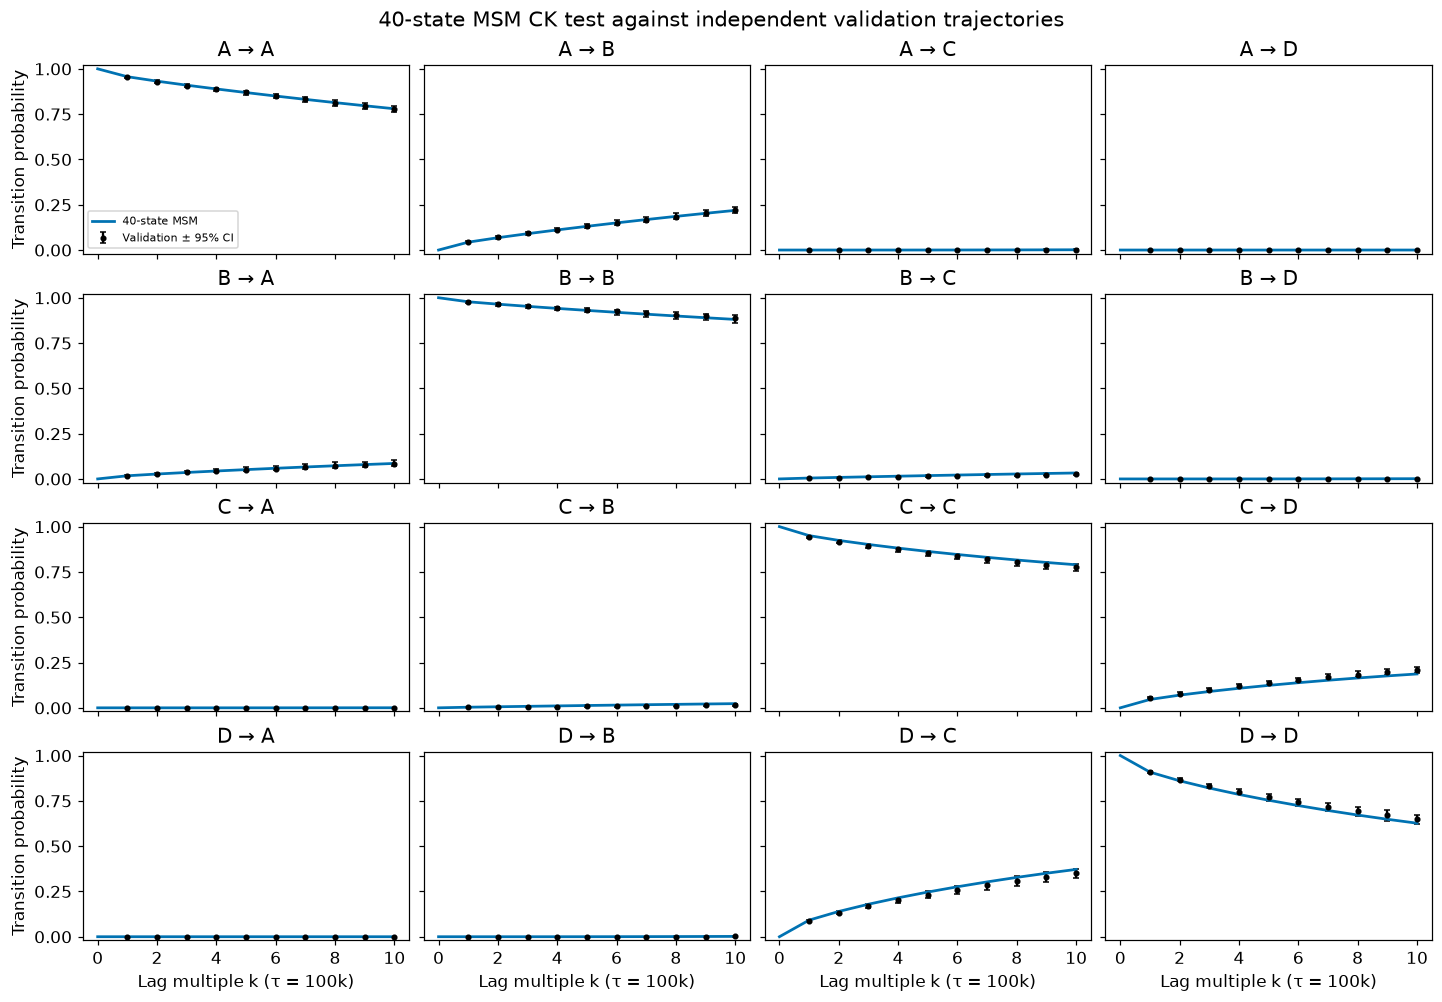

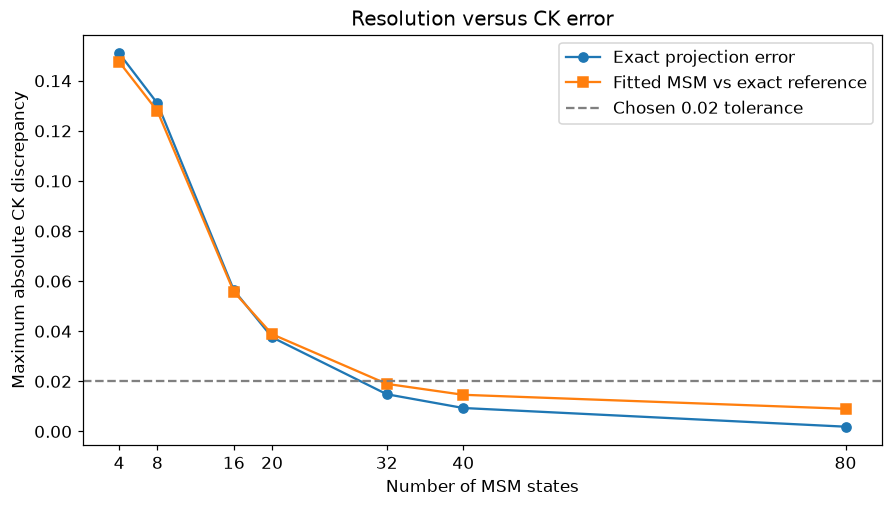

In [ ]:
# CK test for all 16 A-D transitions at the selected 40-state resolution.
M_SELECTED = 40
pred_selected = ck_results[M_SELECTED]["prediction"]
fig, axes = plt.subplots(4, 4, figsize=(13, 9), sharex=True, sharey=True,
                         layout="constrained")
for i in range(4):
    for j in range(4):
        ax = axes[i, j]
        ks = np.arange(1, 11)
        means = np.array([validation_mean[100*k][i, j] for k in ks])
        lows = np.array([validation_ci[100*k][0, i, j] for k in ks])
        highs = np.array([validation_ci[100*k][1, i, j] for k in ks])
        ax.errorbar(ks, means, yerr=[means-lows, highs-means],
                    fmt="ko", ms=3, capsize=2, label="Validation ± 95% CI")
        ax.plot(np.arange(11), pred_selected[:, i, j], color="#0072b2",
                lw=1.8, label="40-state MSM")
        ax.set(title=f"{BASINS[i]} → {BASINS[j]}", ylim=(-0.02, 1.02))
        if j == 0: ax.set_ylabel("Transition probability")
        if i == 3: ax.set_xlabel("Lag multiple k (τ = 100k)")
axes[0, 0].legend(fontsize=7, loc="best")
fig.suptitle("40-state MSM CK test against independent validation trajectories", fontsize=14)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ms = [m for m in candidate_M if "prediction" in ck_results[m]]
ax.plot(ms, [ck_results[m]["max_error_exact_projection"] for m in ms],
        "o-", label="Exact projection error")
ax.plot(ms, [ck_results[m]["max_error_exact"] for m in ms],
        "s-", label="Fitted MSM vs exact reference")
ax.axhline(0.02, color="0.5", ls="--", label="Chosen 0.02 tolerance")
ax.set(xlabel="Number of MSM states", ylabel="Maximum absolute CK discrepancy",
       title="Resolution versus CK error", xticks=ms)
ax.legend()
plt.show()


The 40-state model is the best-supported practical choice in this experiment: its CK curves are closer to the reference than the 32-state fit, while the 80-state model is too sparsely sampled to be a reliable choice. The idealized exact-projection calculation reaches the 0.02 tolerance at 32 states, but the 40-state fitted model is more conservative in terms of uncertainty, giving better agreement with independent validation (maximum discrepancy 0.0217 versus 0.0274).